In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
files = [
    "../data2/prices_round_2_day_-1.csv",
    "../data2/prices_round_2_day_0.csv",
    "../data2/prices_round_2_day_1.csv",
]

datasets = {}

for file in files:
    df = pd.read_csv(file, sep=";")
    day = df["day"].iloc[0]
    datasets[day] = df


PRODUCT ASH_COATED_OSMIUM | DAY -1
count     9985.000000
mean     10000.825088
std          4.466929
min       9981.000000
25%       9998.000000
50%      10001.000000
75%      10003.500000
max      10020.000000
Name: mid_price, dtype: float64


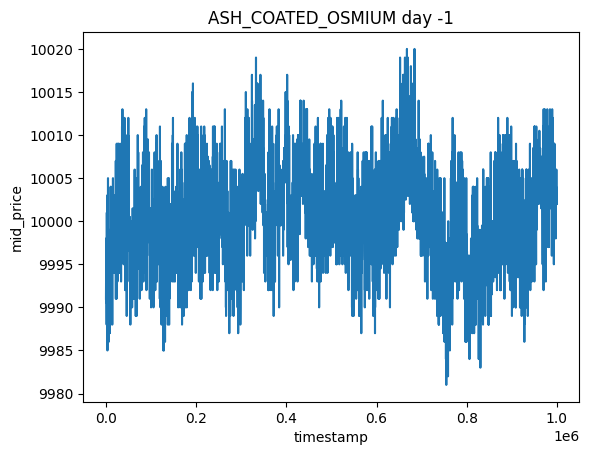


PRODUCT ASH_COATED_OSMIUM | DAY 0
count     9984.000000
mean     10001.607372
std          5.659611
min       9979.000000
25%       9998.375000
50%      10002.000000
75%      10005.000000
max      10023.000000
Name: mid_price, dtype: float64


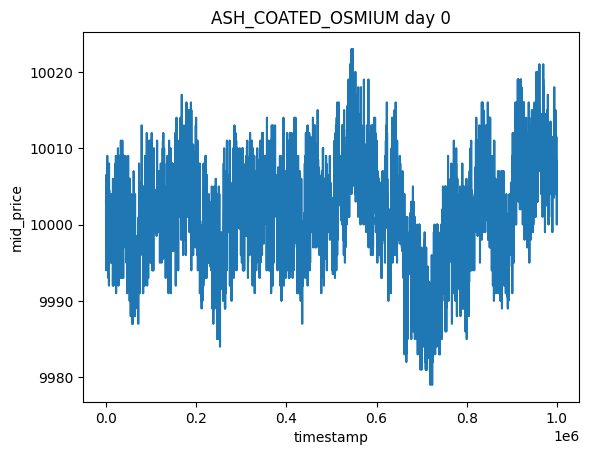


PRODUCT ASH_COATED_OSMIUM | DAY 1
count     9978.000000
mean     10000.205402
std          5.018676
min       9980.000000
25%       9997.000000
50%      10000.000000
75%      10004.000000
max      10019.000000
Name: mid_price, dtype: float64


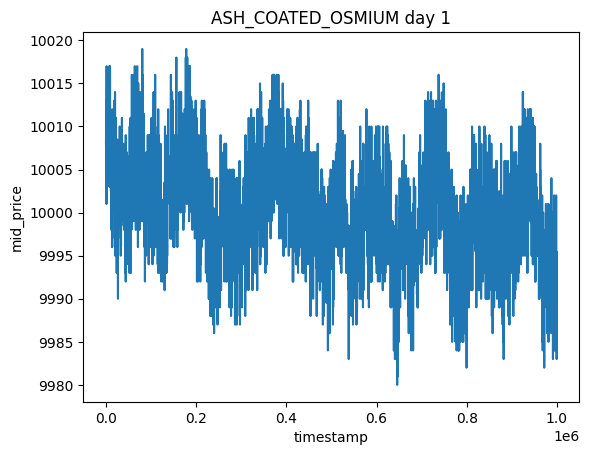

In [3]:
products = ["ASH_COATED_OSMIUM"]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        print(f"\nPRODUCT {product} | DAY {day}")
        print(df_p["mid_price"].describe())

        plt.figure()
        plt.plot(df_p["timestamp"], df_p["mid_price"])
        plt.title(f"{product} day {day}")
        plt.xlabel("timestamp")
        plt.ylabel("mid_price")
        plt.show()

In [4]:
import numpy as np

summary_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value = round(df_p["mid_price"].median())

        df_p["future_mid"] = df_p["mid_price"].shift(-1)
        df_p["future_change"] = df_p["future_mid"] - df_p["mid_price"]

        cheap = df_p["mid_price"] <= fair_value - 2
        expensive = df_p["mid_price"] >= fair_value + 2

        cheap_edge = df_p.loc[cheap, "future_change"].mean()
        expensive_edge = df_p.loc[expensive, "future_change"].mean()

        # 1) Tradability and execution-cost proxies from top-of-book fields.
        if {"bid_price_1", "ask_price_1"}.issubset(df_p.columns):
            spread = (df_p["ask_price_1"] - df_p["bid_price_1"]).astype(float)
            spread_mean = spread.mean()
            spread_p90 = spread.quantile(0.90)
            spread_nonzero_freq = (spread > 0).mean()
        else:
            spread_mean = np.nan
            spread_p90 = np.nan
            spread_nonzero_freq = np.nan

        if {"bid_volume_1", "ask_volume_1"}.issubset(df_p.columns):
            top_depth = (df_p["bid_volume_1"] + df_p["ask_volume_1"]).astype(float)
            top_depth_mean = top_depth.mean()
            top_depth_p10 = top_depth.quantile(0.10)
        else:
            top_depth_mean = np.nan
            top_depth_p10 = np.nan

        # Conservative round-trip crossing cost proxy in price units.
        roundtrip_cost_proxy = spread_mean

        cheap_edge_net = cheap_edge - roundtrip_cost_proxy if pd.notna(roundtrip_cost_proxy) else np.nan
        expensive_edge_net = (-expensive_edge) - roundtrip_cost_proxy if pd.notna(roundtrip_cost_proxy) else np.nan

        # 2) Signal quality / stability metrics.
        mid_change = df_p["mid_price"].diff()
        return_autocorr_lag1 = mid_change.autocorr(lag=1)

        cheap_count = int(cheap.sum())
        expensive_count = int(expensive.sum())
        cheap_hit_rate = (df_p.loc[cheap, "future_change"] > 0).mean() if cheap_count > 0 else np.nan
        expensive_hit_rate = (df_p.loc[expensive, "future_change"] < 0).mean() if expensive_count > 0 else np.nan

        deviation = (df_p["mid_price"] - fair_value).astype(float)
        x_t = deviation.iloc[:-1]
        x_next = deviation.iloc[1:]
        valid = x_t.notna() & x_next.notna()

        if valid.sum() >= 10:
            beta = np.polyfit(x_t[valid].to_numpy(), x_next[valid].to_numpy(), 1)[0]
        else:
            beta = np.nan

        if pd.notna(beta) and (0 < beta < 1):
            half_life = -np.log(2) / np.log(beta)
        else:
            half_life = np.nan

        summary_rows.append({
            "product": product,
            "day": day,
            "count": df_p["mid_price"].count(),
            "mean": df_p["mid_price"].mean(),
            "median": df_p["mid_price"].median(),
            "std": df_p["mid_price"].std(),
            "min": df_p["mid_price"].min(),
            "max": df_p["mid_price"].max(),
            "fair_value": fair_value,
            "cheap_freq": cheap.mean(),
            "expensive_freq": expensive.mean(),
            "cheap_edge": cheap_edge,
            "expensive_edge": expensive_edge,
            "spread_mean": spread_mean,
            "spread_p90": spread_p90,
            "spread_nonzero_freq": spread_nonzero_freq,
            "top_depth_mean": top_depth_mean,
            "top_depth_p10": top_depth_p10,
            "roundtrip_cost_proxy": roundtrip_cost_proxy,
            "cheap_edge_net": cheap_edge_net,
            "expensive_edge_net": expensive_edge_net,
            "return_autocorr_lag1": return_autocorr_lag1,
            "cheap_count": cheap_count,
            "expensive_count": expensive_count,
            "cheap_hit_rate": cheap_hit_rate,
            "expensive_hit_rate": expensive_hit_rate,
            "deviation_ar1_beta": beta,
            "half_life_steps": half_life,
        })

summary_df = pd.DataFrame(summary_rows).sort_values(["product", "day"])
summary_df

,product,day,count,mean,median,std,min,max,fair_value,cheap_freq,...,roundtrip_cost_proxy,cheap_edge_net,expensive_edge_net,return_autocorr_lag1,cheap_count,expensive_count,cheap_hit_rate,expensive_hit_rate,deviation_ar1_beta,half_life_steps
0,ASH_COATED_OSMIUM,-1,9985,10000.825088,10001.0,4.466929,9981.0,10020.0,10001,0.346620,...,16.223990,-14.959327,-14.870195,-0.506307,3461,3201,0.488298,0.492659,1.0,NaN
1,ASH_COATED_OSMIUM,0,9984,10001.607372,10002.0,5.659611,9979.0,10023.0,10002,0.371595,...,16.249541,-15.225552,-15.067490,-0.506373,3710,3327,0.461186,0.481515,1.0,NaN
2,ASH_COATED_OSMIUM,1,9978,10000.205402,10000.0,5.018676,9980.0,10019.0,10000,0.351072,...,16.228891,-15.100107,-15.198165,-0.490528,3503,3938,0.460177,0.448451,1.0,NaN


## Notes for points 3 to 6

- Point 3: check regime behavior by splitting each day into time buckets and comparing price levels, signal frequency, and edge inside each bucket.
- Point 4: use a simple persistent inventory simulation to measure PnL, drawdown, turnover, and exposure risk from the cheap/expensive signal.
- Point 5: sweep entry thresholds and holding horizons to see where the mean-reversion signal is strongest and how fast reversion usually happens.
- Point 6: compare fixed-fair-value, rolling-fair-value, and leave-one-day-out results so we can catch leakage and parameter sensitivity before building a bot.

In [5]:
import numpy as np
from IPython.display import display

def first_reversion_steps(prices, fair_value, side, max_steps=20):
    values = prices.to_numpy()
    results = []
    for i in range(len(values)):
        window = values[i + 1 : i + max_steps + 1]
        if side == "long":
            hits = np.where(window >= fair_value)[0]
        else:
            hits = np.where(window <= fair_value)[0]
        results.append(hits[0] + 1 if len(hits) else np.nan)
    return pd.Series(results, index=prices.index)

# Point 3: regime behavior by time bucket.
regime_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value = round(df_p["mid_price"].median())
        df_p["future_mid"] = df_p["mid_price"].shift(-1)
        df_p["future_change"] = df_p["future_mid"] - df_p["mid_price"]
        df_p["time_bucket"] = pd.qcut(df_p["timestamp"], q=4, labels=False, duplicates="drop")

        for bucket, bucket_df in df_p.groupby("time_bucket", dropna=False):
            if bucket_df.empty:
                continue

            cheap_bucket = bucket_df["mid_price"] <= fair_value - 2
            expensive_bucket = bucket_df["mid_price"] >= fair_value + 2

            regime_rows.append({
                "product": product,
                "day": day,
                "bucket": bucket,
                "start_ts": bucket_df["timestamp"].min(),
                "end_ts": bucket_df["timestamp"].max(),
                "count": len(bucket_df),
                "mean_mid_price": bucket_df["mid_price"].mean(),
                "std_mid_price": bucket_df["mid_price"].std(),
                "cheap_freq": cheap_bucket.mean(),
                "expensive_freq": expensive_bucket.mean(),
                "cheap_edge": bucket_df.loc[cheap_bucket, "future_change"].mean(),
                "expensive_edge": bucket_df.loc[expensive_bucket, "future_change"].mean(),
            })

regime_df = pd.DataFrame(regime_rows).sort_values(["product", "day", "bucket"])

# Point 4: simple inventory and risk simulation.
risk_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value = round(df_p["mid_price"].median())
        inventory = []
        position = 0

        for price in df_p["mid_price"]:
            if position > 0 and price >= fair_value:
                position -= 1
            elif position < 0 and price <= fair_value:
                position += 1

            if price <= fair_value - 2 and position < 3:
                position += 1
            elif price >= fair_value + 2 and position > -3:
                position -= 1

            inventory.append(position)

        df_p["sim_inventory"] = inventory
        df_p["sim_pnl"] = df_p["sim_inventory"].shift(1).fillna(0) * df_p["mid_price"].diff().fillna(0)
        df_p["sim_cum_pnl"] = df_p["sim_pnl"].cumsum()
        df_p["sim_drawdown"] = df_p["sim_cum_pnl"] - df_p["sim_cum_pnl"].cummax()

        risk_rows.append({
            "product": product,
            "day": day,
            "mean_inventory": df_p["sim_inventory"].mean(),
            "mean_abs_inventory": df_p["sim_inventory"].abs().mean(),
            "max_inventory": df_p["sim_inventory"].abs().max(),
            "trade_count": df_p["sim_inventory"].diff().abs().fillna(0).sum(),
            "total_pnl": df_p["sim_pnl"].sum(),
            "mean_pnl": df_p["sim_pnl"].mean(),
            "pnl_std": df_p["sim_pnl"].std(),
            "win_rate": (df_p["sim_pnl"] > 0).mean(),
            "max_drawdown": df_p["sim_drawdown"].min(),
        })

risk_df = pd.DataFrame(risk_rows).sort_values(["product", "day"])

# Point 5: threshold and holding-period sweep for entry/exit design.
entry_exit_rows = []
thresholds = [1, 2, 3, 4, 5]
horizons = [1, 2, 5, 10, 20]
max_horizon = max(horizons)

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value = round(df_p["mid_price"].median())
        long_reversion_steps = first_reversion_steps(df_p["mid_price"], fair_value, "long", max_steps=max_horizon)
        short_reversion_steps = first_reversion_steps(df_p["mid_price"], fair_value, "short", max_steps=max_horizon)

        for threshold in thresholds:
            cheap_entry = df_p["mid_price"] <= fair_value - threshold
            expensive_entry = df_p["mid_price"] >= fair_value + threshold

            for horizon in horizons:
                future_change_h = df_p["mid_price"].shift(-horizon) - df_p["mid_price"]

                entry_exit_rows.append({
                    "product": product,
                    "day": day,
                    "threshold": threshold,
                    "horizon": horizon,
                    "cheap_entry_count": int(cheap_entry.sum()),
                    "expensive_entry_count": int(expensive_entry.sum()),
                    "cheap_edge_h": future_change_h.loc[cheap_entry].mean(),
                    "expensive_edge_h": (-future_change_h.loc[expensive_entry]).mean(),
                    "cheap_hit_rate_h": (future_change_h.loc[cheap_entry] > 0).mean(),
                    "expensive_hit_rate_h": (future_change_h.loc[expensive_entry] < 0).mean(),
                    "avg_reversion_steps_long": long_reversion_steps.loc[cheap_entry].mean(),
                    "avg_reversion_steps_short": short_reversion_steps.loc[expensive_entry].mean(),
                })

entry_exit_df = pd.DataFrame(entry_exit_rows).sort_values(["product", "day", "threshold", "horizon"])

# Point 6: leakage and out-of-sample checks.
validation_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value_fixed = round(df_p["mid_price"].median())
        future_change_1 = df_p["mid_price"].shift(-1) - df_p["mid_price"]

        fixed_cheap = df_p["mid_price"] <= fair_value_fixed - 2
        fixed_expensive = df_p["mid_price"] >= fair_value_fixed + 2

        rolling_fair_value = df_p["mid_price"].rolling(window=200, min_periods=50).median().shift(1)
        rolling_cheap = df_p["mid_price"] <= rolling_fair_value - 2
        rolling_expensive = df_p["mid_price"] >= rolling_fair_value + 2

        train_days = [train_day for train_day in datasets if train_day != day]
        train_df = pd.concat(
            [datasets[train_day][datasets[train_day]["product"] == product] for train_day in train_days],
            axis=0,
        )
        train_df = train_df[train_df["mid_price"] > 0]
        train_fair_value = round(train_df["mid_price"].median())

        oos_cheap = df_p["mid_price"] <= train_fair_value - 2
        oos_expensive = df_p["mid_price"] >= train_fair_value + 2

        validation_rows.append({
            "product": product,
            "day": day,
            "mode": "fixed_in_sample",
            "lookahead_safe": False,
            "fair_value_used": fair_value_fixed,
            "cheap_freq": fixed_cheap.mean(),
            "expensive_freq": fixed_expensive.mean(),
            "cheap_edge": future_change_1.loc[fixed_cheap].mean(),
            "expensive_edge": future_change_1.loc[fixed_expensive].mean(),
        })

        validation_rows.append({
            "product": product,
            "day": day,
            "mode": "rolling_past_only",
            "lookahead_safe": True,
            "fair_value_used": rolling_fair_value.mean(),
            "cheap_freq": rolling_cheap.mean(),
            "expensive_freq": rolling_expensive.mean(),
            "cheap_edge": future_change_1.loc[rolling_cheap].mean(),
            "expensive_edge": future_change_1.loc[rolling_expensive].mean(),
        })

        validation_rows.append({
            "product": product,
            "day": day,
            "mode": "leave_one_day_out",
            "lookahead_safe": True,
            "fair_value_used": train_fair_value,
            "cheap_freq": oos_cheap.mean(),
            "expensive_freq": oos_expensive.mean(),
            "cheap_edge": future_change_1.loc[oos_cheap].mean(),
            "expensive_edge": future_change_1.loc[oos_expensive].mean(),
        })

validation_df = pd.DataFrame(validation_rows).sort_values(["product", "day", "mode"])

entry_exit_summary = entry_exit_df.groupby(["threshold", "horizon"])[
    ["cheap_edge_h", "expensive_edge_h", "cheap_hit_rate_h", "expensive_hit_rate_h"]
] .mean().reset_index()
display(regime_df)
display(risk_df)
display(entry_exit_summary)
display(validation_df)

,product,day,bucket,start_ts,end_ts,count,mean_mid_price,std_mid_price,cheap_freq,expensive_freq,cheap_edge,expensive_edge
0,ASH_COATED_OSMIUM,-1,0,0,249900,2497,10000.051262,3.723272,0.362835,0.195435,1.418322,-2.246926
1,ASH_COATED_OSMIUM,-1,1,250000,499800,2496,10002.440705,3.920054,0.193910,0.463542,1.783058,-0.851340
2,ASH_COATED_OSMIUM,-1,2,499900,749900,2496,10001.981370,4.688595,0.296074,0.429487,1.495264,-1.046642
3,ASH_COATED_OSMIUM,-1,3,750000,999900,2496,9998.827324,4.481853,0.533654,0.193910,0.843844,-2.334711
4,ASH_COATED_OSMIUM,0,0,0,250100,2496,10001.084335,4.025968,0.379407,0.237179,1.282471,-1.732264
5,ASH_COATED_OSMIUM,0,1,250200,500000,2496,10001.702524,3.550572,0.262019,0.224359,1.843272,-2.198214
6,ASH_COATED_OSMIUM,0,2,500100,750000,2496,10000.376002,7.922378,0.461138,0.386218,0.567767,-0.817946
7,ASH_COATED_OSMIUM,0,3,750100,999900,2496,10003.266627,5.659539,0.383814,0.485176,0.757307,-0.732645
8,ASH_COATED_OSMIUM,1,0,0,250400,2495,10003.408216,4.554534,0.129058,0.662926,2.532609,-0.691657
9,ASH_COATED_OSMIUM,1,1,250500,500300,2494,10000.507819,4.310530,0.316359,0.418204,1.132446,-0.988495


,product,day,mean_inventory,mean_abs_inventory,max_inventory,trade_count,total_pnl,mean_pnl,pnl_std,win_rate,max_drawdown
0,ASH_COATED_OSMIUM,-1,0.072909,2.152429,3,2778.0,9446.5,0.946069,8.412146,0.333200,-52.5
1,ASH_COATED_OSMIUM,0,0.135317,2.214643,3,2435.0,8290.0,0.830329,8.700203,0.339042,-66.0
2,ASH_COATED_OSMIUM,1,-0.154640,2.345260,3,2442.0,8699.0,0.871818,8.899622,0.336440,-53.0


,threshold,horizon,cheap_edge_h,expensive_edge_h,cheap_hit_rate_h,expensive_hit_rate_h
0,1,1,0.947093,0.965231,0.451033,0.452261
1,1,2,0.949720,0.963155,0.471928,0.472790
2,1,5,0.996840,1.026186,0.499991,0.506013
3,1,10,1.037904,1.069416,0.524011,0.526845
4,1,20,1.127908,1.160322,0.551670,0.548831
5,2,1,1.139145,1.188857,0.469887,0.474208
6,2,2,1.143002,1.185486,0.490933,0.493855
7,2,5,1.198372,1.261556,0.520844,0.528328
8,2,10,1.229061,1.300790,0.544215,0.545473
9,2,20,1.345870,1.395078,0.571732,0.567786


,product,day,mode,lookahead_safe,fair_value_used,cheap_freq,expensive_freq,cheap_edge,expensive_edge
0,ASH_COATED_OSMIUM,-1,fixed_in_sample,False,10001.000000,0.346620,0.320581,1.264663,-1.353796
2,ASH_COATED_OSMIUM,-1,leave_one_day_out,True,10001.000000,0.346620,0.320581,1.264663,-1.353796
1,ASH_COATED_OSMIUM,-1,rolling_past_only,True,10000.795093,0.263896,0.282524,1.793359,-1.627260
3,ASH_COATED_OSMIUM,0,fixed_in_sample,False,10002.000000,0.371595,0.333233,1.023989,-1.182051
5,ASH_COATED_OSMIUM,0,leave_one_day_out,True,10001.000000,0.302784,0.413261,1.125207,-0.961939
4,ASH_COATED_OSMIUM,0,rolling_past_only,True,10001.524612,0.256911,0.271534,1.840546,-1.666728
6,ASH_COATED_OSMIUM,1,fixed_in_sample,False,10000.000000,0.351072,0.394668,1.128784,-1.030726
8,ASH_COATED_OSMIUM,1,leave_one_day_out,True,10001.000000,0.431549,0.319904,0.965854,-1.230576
7,ASH_COATED_OSMIUM,1,rolling_past_only,True,10000.316302,0.304770,0.280617,1.479283,-1.689286


## ASH metric collection

This section collects the additional ASH diagnostics we discussed: wall-based fair value, depth-weighted fair value, imbalance, rolling volatility, regime splits, and distance-to-fair-value forward returns.

In [6]:
import numpy as np
from IPython.display import display

def _available_level_pairs(df_p, side, max_levels=5):
    price_cols = []
    volume_cols = []
    for i in range(1, max_levels + 1):
        pcol = f"{side}_price_{i}"
        vcol = f"{side}_volume_{i}"
        if pcol in df_p.columns and vcol in df_p.columns:
            price_cols.append(pcol)
            volume_cols.append(vcol)
    return price_cols, volume_cols

def _depth_weighted_mid(df_p, max_levels=5):
    bid_price_cols, bid_volume_cols = _available_level_pairs(df_p, "bid", max_levels)
    ask_price_cols, ask_volume_cols = _available_level_pairs(df_p, "ask", max_levels)
    if not bid_price_cols or not ask_price_cols:
        return pd.Series(np.nan, index=df_p.index)

    bid_notional = pd.Series(0.0, index=df_p.index)
    bid_volume = pd.Series(0.0, index=df_p.index)
    ask_notional = pd.Series(0.0, index=df_p.index)
    ask_volume = pd.Series(0.0, index=df_p.index)

    for pcol, vcol in zip(bid_price_cols, bid_volume_cols):
        volumes = df_p[vcol].abs().astype(float)
        bid_notional = bid_notional + df_p[pcol].astype(float) * volumes
        bid_volume = bid_volume + volumes

    for pcol, vcol in zip(ask_price_cols, ask_volume_cols):
        volumes = df_p[vcol].abs().astype(float)
        ask_notional = ask_notional + df_p[pcol].astype(float) * volumes
        ask_volume = ask_volume + volumes

    total_volume = bid_volume + ask_volume
    with np.errstate(divide="ignore", invalid="ignore"):
        depth_mid = (bid_notional + ask_notional) / total_volume
    return depth_mid

def _wall_prices(df_p, side, max_levels=5):
    price_cols, volume_cols = _available_level_pairs(df_p, side, max_levels)
    if not price_cols:
        return pd.Series(np.nan, index=df_p.index)

    volume_frame = pd.DataFrame(
        {vcol: df_p[vcol].abs().astype(float) for vcol in volume_cols}, index=df_p.index
    )
    all_missing = volume_frame.isna().all(axis=1)
    max_col = volume_frame.fillna(-np.inf).idxmax(axis=1)
    wall_price = pd.Series(np.nan, index=df_p.index, dtype=float)
    for pcol, vcol in zip(price_cols, volume_cols):
        mask = (max_col == vcol) & (~all_missing)
        if mask.any():
            wall_price.loc[mask] = df_p.loc[mask, pcol].astype(float)
    return wall_price

def _top_level_imbalance(df_p):
    bid_price_cols, bid_volume_cols = _available_level_pairs(df_p, "bid", 1)
    ask_price_cols, ask_volume_cols = _available_level_pairs(df_p, "ask", 1)
    if not bid_volume_cols or not ask_volume_cols:
        return pd.Series(np.nan, index=df_p.index)
    bid_volume = df_p[bid_volume_cols[0]].abs().astype(float)
    ask_volume = df_p[ask_volume_cols[0]].abs().astype(float)
    denom = bid_volume + ask_volume
    with np.errstate(divide="ignore", invalid="ignore"):
        imbalance = (bid_volume - ask_volume) / denom
    return imbalance

def _multi_level_imbalance(df_p, max_levels=5):
    _, bid_volume_cols = _available_level_pairs(df_p, "bid", max_levels)
    _, ask_volume_cols = _available_level_pairs(df_p, "ask", max_levels)
    if not bid_volume_cols or not ask_volume_cols:
        return pd.Series(np.nan, index=df_p.index)
    bid_volume = pd.Series(0.0, index=df_p.index)
    ask_volume = pd.Series(0.0, index=df_p.index)
    for vcol in bid_volume_cols:
        bid_volume = bid_volume + df_p[vcol].abs().astype(float)
    for vcol in ask_volume_cols:
        ask_volume = ask_volume + df_p[vcol].abs().astype(float)
    denom = bid_volume + ask_volume
    with np.errstate(divide="ignore", invalid="ignore"):
        imbalance = (bid_volume - ask_volume) / denom
    return imbalance

def _lagged_autocorr(series, lag):
    return series.autocorr(lag=lag)

def _reversion_beta(deviation):
    x_t = deviation.iloc[:-1]
    x_next = deviation.iloc[1:]
    valid = x_t.notna() & x_next.notna()
    if valid.sum() < 10:
        return np.nan
    return np.polyfit(x_t[valid].to_numpy(), x_next[valid].to_numpy(), 1)[0]

def _half_life_from_beta(beta):
    if pd.notna(beta) and 0 < beta < 1:
        return -np.log(2) / np.log(beta)
    return np.nan

ash_feature_rows = []
ash_regime_rows = []
ash_bucket_rows = []
ash_rolling_rows = []

bucket_edges = [-np.inf, -5, -3, -2, -1, 0, 1, 2, 3, 5, np.inf]
bucket_labels = ["<=-5", "-5:-3", "-3:-2", "-2:-1", "-1:0", "0:1", "1:2", "2:3", "3:5", ">=5"]
horizons = [1, 2, 5, 10]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        if df_p.empty:
            continue

        mid = df_p["mid_price"].astype(float)
        mid_change = mid.diff()

        wall_bid = _wall_prices(df_p, "bid", max_levels=5)
        wall_ask = _wall_prices(df_p, "ask", max_levels=5)
        wall_mid = (wall_bid + wall_ask) / 2
        depth_mid = _depth_weighted_mid(df_p, max_levels=5)

        if {"bid_price_1", "ask_price_1"}.issubset(df_p.columns):
            spread_1 = (df_p["ask_price_1"] - df_p["bid_price_1"]).astype(float)
        else:
            spread_1 = pd.Series(np.nan, index=df_p.index)

        spread_wall = wall_ask - wall_bid
        top_imbalance = _top_level_imbalance(df_p)
        multi_imbalance = _multi_level_imbalance(df_p, max_levels=5)

        rolling_vol_20 = mid_change.rolling(20, min_periods=10).std()
        rolling_vol_50 = mid_change.rolling(50, min_periods=20).std()
        rolling_vol_200 = mid_change.rolling(200, min_periods=50).std()

        deviation_wall = mid - wall_mid
        deviation_depth = mid - depth_mid

        beta_wall = _reversion_beta(deviation_wall)
        beta_depth = _reversion_beta(deviation_depth)

        ash_feature_rows.append({
            "product": product,
            "day": day,
            "count": len(df_p),
            "mid_mean": mid.mean(),
            "mid_median": mid.median(),
            "mid_std": mid.std(),
            "wall_mid_mean": wall_mid.mean(),
            "depth_mid_mean": depth_mid.mean(),
            "wall_minus_mid_mean": (wall_mid - mid).mean(),
            "depth_minus_mid_mean": (depth_mid - mid).mean(),
            "spread_1_mean": spread_1.mean(),
            "spread_1_p90": spread_1.quantile(0.90),
            "spread_wall_mean": spread_wall.mean(),
            "spread_wall_p90": spread_wall.quantile(0.90),
            "top_imbalance_mean": top_imbalance.mean(),
            "multi_imbalance_mean": multi_imbalance.mean(),
            "return_autocorr_lag1": _lagged_autocorr(mid_change, 1),
            "return_autocorr_lag5": _lagged_autocorr(mid_change, 5),
            "rolling_vol_20_mean": rolling_vol_20.mean(),
            "rolling_vol_50_mean": rolling_vol_50.mean(),
            "rolling_vol_200_mean": rolling_vol_200.mean(),
            "reversion_beta_wall": beta_wall,
            "half_life_wall": _half_life_from_beta(beta_wall),
            "reversion_beta_depth": beta_depth,
            "half_life_depth": _half_life_from_beta(beta_depth),
        })

        time_bucket = pd.qcut(df_p["timestamp"], q=4, labels=False, duplicates="drop")
        for bucket, bucket_df in df_p.groupby(time_bucket, dropna=False):
            if bucket_df.empty:
                continue

            bucket_mid = bucket_df["mid_price"].astype(float)
            bucket_wall_mid = wall_mid.loc[bucket_df.index]
            bucket_dev = bucket_mid - bucket_wall_mid
            bucket_change = bucket_mid.diff()
            ash_regime_rows.append({
                "product": product,
                "day": day,
                "bucket": bucket,
                "start_ts": bucket_df["timestamp"].min(),
                "end_ts": bucket_df["timestamp"].max(),
                "count": len(bucket_df),
                "mid_mean": bucket_mid.mean(),
                "wall_mid_mean": bucket_wall_mid.mean(),
                "deviation_mean": bucket_dev.mean(),
                "spread_mean": (bucket_df["ask_price_1"] - bucket_df["bid_price_1"]).mean() if {"bid_price_1", "ask_price_1"}.issubset(bucket_df.columns) else np.nan,
                "imbalance_mean": top_imbalance.loc[bucket_df.index].mean(),
                "rolling_vol_50_mean": bucket_change.rolling(50, min_periods=20).std().mean(),
                "return_autocorr_lag1": _lagged_autocorr(bucket_change, 1),
                "reversion_beta_wall": _reversion_beta(bucket_dev),
                "half_life_wall": _half_life_from_beta(_reversion_beta(bucket_dev)),
            })

        for horizon in horizons:
            future_change = mid.shift(-horizon) - mid
            bucketed = pd.cut(deviation_wall, bins=bucket_edges, labels=bucket_labels, include_lowest=True)
            for bucket in bucket_labels:
                mask = bucketed == bucket
                if mask.sum() == 0:
                    continue

                future_subset = future_change.loc[mask]
                ash_bucket_rows.append({
                    "product": product,
                    "day": day,
                    "horizon": horizon,
                    "distance_bucket": bucket,
                    "count": int(mask.sum()),
                    "mean_deviation": deviation_wall.loc[mask].mean(),
                    "mean_future_change": future_subset.mean(),
                    "hit_rate_up": (future_subset > 0).mean(),
                    "hit_rate_down": (future_subset < 0).mean(),
                    "abs_future_change": future_subset.abs().mean(),
                    "top_imbalance_mean": top_imbalance.loc[mask].mean(),
                    "spread_1_mean": spread_1.loc[mask].mean() if spread_1.notna().any() else np.nan,
                })

        ash_rolling_rows.append({
            "product": product,
            "day": day,
            "rolling_vol_20_mean": rolling_vol_20.mean(),
            "rolling_vol_20_p90": rolling_vol_20.quantile(0.90),
            "rolling_vol_50_mean": rolling_vol_50.mean(),
            "rolling_vol_50_p90": rolling_vol_50.quantile(0.90),
            "rolling_vol_200_mean": rolling_vol_200.mean(),
            "rolling_vol_200_p90": rolling_vol_200.quantile(0.90),
            "return_autocorr_lag1": _lagged_autocorr(mid_change, 1),
            "return_autocorr_lag5": _lagged_autocorr(mid_change, 5),
        })

ash_feature_df = pd.DataFrame(ash_feature_rows).sort_values(["product", "day"])
ash_regime_df = pd.DataFrame(ash_regime_rows).sort_values(["product", "day", "bucket"])
ash_bucket_df = pd.DataFrame(ash_bucket_rows).sort_values(["product", "day", "horizon", "distance_bucket"])
ash_rolling_df = pd.DataFrame(ash_rolling_rows).sort_values(["product", "day"])

display(ash_feature_df)
display(ash_regime_df)
display(ash_bucket_df.groupby(["horizon", "distance_bucket"])[["mean_future_change", "hit_rate_up", "hit_rate_down"]].mean().reset_index())
display(ash_rolling_df)

,product,day,count,mid_mean,mid_median,mid_std,wall_mid_mean,depth_mid_mean,wall_minus_mid_mean,depth_minus_mid_mean,...,multi_imbalance_mean,return_autocorr_lag1,return_autocorr_lag5,rolling_vol_20_mean,rolling_vol_50_mean,rolling_vol_200_mean,reversion_beta_wall,half_life_wall,reversion_beta_depth,half_life_depth
0,ASH_COATED_OSMIUM,-1,9985,10000.825088,10001.0,4.466929,10000.853849,NaN,0.025712,NaN,...,NaN,-0.506307,0.006539,3.560446,3.649705,3.696879,1.0,NaN,NaN,NaN
1,ASH_COATED_OSMIUM,0,9984,10001.607372,10002.0,5.659611,10001.623258,NaN,0.044669,NaN,...,NaN,-0.506373,-0.003799,3.531145,3.621341,3.680005,1.0,5.727812e+13,NaN,NaN
2,ASH_COATED_OSMIUM,1,9978,10000.205402,10000.0,5.018676,10000.185262,NaN,0.035001,NaN,...,NaN,-0.490528,-0.040082,3.555763,3.642275,3.674128,1.0,NaN,NaN,NaN


,product,day,bucket,start_ts,end_ts,count,mid_mean,wall_mid_mean,deviation_mean,spread_mean,imbalance_mean,rolling_vol_50_mean,return_autocorr_lag1,reversion_beta_wall,half_life_wall
0,ASH_COATED_OSMIUM,-1,0,0,249900,2497,10000.051262,10000.251416,-0.080174,16.201307,0.006790,3.809923,-0.503214,1.0,NaN
1,ASH_COATED_OSMIUM,-1,1,250000,499800,2496,10002.440705,10002.386695,0.024464,16.282403,-0.006871,3.426714,-0.512115,1.0,NaN
2,ASH_COATED_OSMIUM,-1,2,499900,749900,2496,10001.981370,10001.977826,-0.011957,16.230870,-0.000405,3.675478,-0.501180,1.0,NaN
3,ASH_COATED_OSMIUM,-1,3,750000,999900,2496,9998.827324,9998.788927,-0.035900,16.180796,-0.002876,3.689356,-0.510674,1.0,NaN
4,ASH_COATED_OSMIUM,0,0,0,250100,2496,10001.084335,10001.147566,-0.078414,16.316674,0.002767,3.536403,-0.498374,1.0,NaN
5,ASH_COATED_OSMIUM,0,1,250200,500000,2496,10001.702524,10001.695577,-0.015828,16.293582,0.001368,3.651168,-0.499860,1.0,NaN
6,ASH_COATED_OSMIUM,0,2,500100,750000,2496,10000.376002,10000.364859,-0.029284,16.199132,0.004012,3.675367,-0.520477,1.0,NaN
7,ASH_COATED_OSMIUM,0,3,750100,999900,2496,10003.266627,10003.273978,-0.054839,16.188817,0.006058,3.632107,-0.507949,1.0,3.121657e+15
8,ASH_COATED_OSMIUM,1,0,0,250400,2495,10003.408216,10003.463976,-0.053168,16.259115,0.004395,3.680103,-0.509558,1.0,NaN
9,ASH_COATED_OSMIUM,1,1,250500,500300,2494,10000.507819,10000.412083,-0.017324,16.290602,0.000064,3.567596,-0.492091,1.0,NaN


,horizon,distance_bucket,mean_future_change,hit_rate_up,hit_rate_down
0,1,-1:0,0.155166,0.381729,0.277280
1,1,-2:-1,0.585215,0.555122,0.206111
2,1,-3:-2,3.493340,0.936301,0.041477
3,1,-5:-3,3.596800,0.938960,0.048918
4,1,0:1,-0.340445,0.209838,0.405019
5,1,1:2,-0.828026,0.147561,0.607708
6,1,2:3,-2.743398,0.068979,0.921192
7,1,3:5,-4.046982,0.050505,0.942630
8,1,<=-5,5.397267,0.957799,0.042201
9,1,>=5,-5.049744,0.061505,0.938495


,product,day,rolling_vol_20_mean,rolling_vol_20_p90,rolling_vol_50_mean,rolling_vol_50_p90,rolling_vol_200_mean,rolling_vol_200_p90,return_autocorr_lag1,return_autocorr_lag5
0,ASH_COATED_OSMIUM,-1,3.560446,5.236109,3.649705,4.657921,3.696879,4.153071,-0.506307,0.006539
1,ASH_COATED_OSMIUM,0,3.531145,5.200961,3.621341,4.740674,3.680005,4.153112,-0.506373,-0.003799
2,ASH_COATED_OSMIUM,1,3.555763,5.164339,3.642275,4.620394,3.674128,4.175602,-0.490528,-0.040082
